### Tutorial for pre-processing single cell dataset 
##### author: Wei Yang 
##### doublet detection updated 10/08/23
##### updated subclustering and raw 12/13/23

In [1]:
import bioalpha
import scanpy as sc
import scipy.io
import matplotlib.pyplot as plt
import numpy as np
import os
import seaborn as sns
import math
import pandas as pd
import sys
from time import perf_counter as pc
import statistics
import re

In [2]:
import warnings
warnings.simplefilter(action='ignore', category=FutureWarning)

In [3]:
exec(open('/scratch/wyang114/bin/_figure_options.py').read())
np.random.seed(2023)
region = 'franken'  #specify region of interest
subregion = 'mdtn'

# Preprocessing

In [5]:
#open raw files of franken of different regions
data_dir = f'/scratch/klwatki5/bbi/regions/mdtn/mdtn_franken_raw.h5ad'
adata = sc.read_h5ad(data_dir)

In [12]:
adata.shape[0]

161951

In [6]:
adata_raw = adata.shape[0]
adata.raw = adata
np.median(adata.obs['n_umi'])

1703.0

In [7]:
df = adata.obs
df_sample = df.groupby('sample_id').size()
adata.obs['total_cell']=adata.obs['sample_id'].map(df_sample)

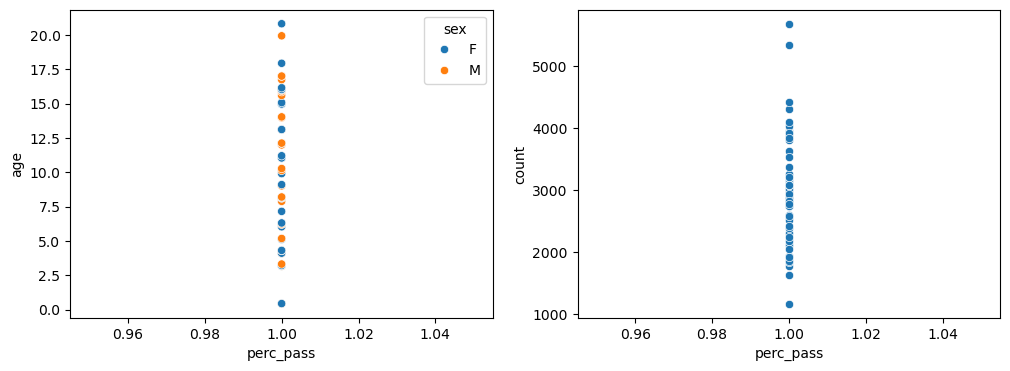

In [8]:
save_sample_stat(adata.obs,['age','sex'],dir=f'/scratch/wyang114/cell-count/all_filter_stats/{region}_{subregion}_original.csv')

In [13]:
# #Check mt%, %intronic, scurblet score and log2umi distribution for the raw dataset
# adata.var['mt'] = adata.var['chromosome_name'] == 'MT'
# sc.pp.calculate_qc_metrics(adata, qc_vars=['mt'], percent_top=None, log1p=False, inplace=True)
# adata.obs['%intronic']=adata.obs['n_intronic_umi']/adata.obs['n_umi']
# adata.obs['log2umi']=[math.log2(i) for i in adata.obs['n_umi']]
# #Visualize distributions
# df=adata.obs
# sns.jointplot(data=df,y='log2umi',x='%intronic',kind='hex')
# sns.jointplot(data=df,y='log2umi',x='scrublet_score',kind='hex')
# sns.jointplot(data=df,y='log2umi',x='n_genes_by_counts',kind='hex')
# sc.pl.violin(adata, ['pct_counts_mt'],jitter=0.1)  

In [15]:
# #Filter out cells with low gene counts
# gene_thre = 100
# low_feature =sum(adata.obs['n_genes_by_counts']<= gene_thre)  #filter cells with <100 genes
# print(f'filter out {low_feature}({low_feature/adata.raw.shape[0]*100}%) cells with low gene counts.')
# adata = adata[adata.obs['n_genes_by_counts']> gene_thre,] 
# del low_feature

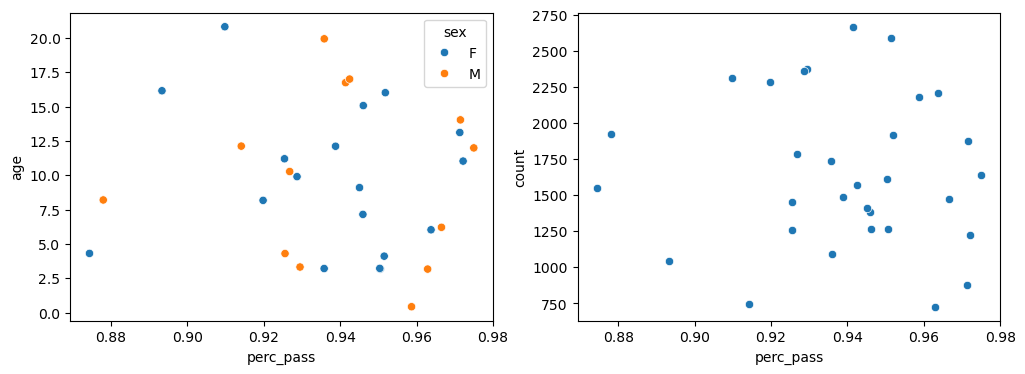

In [17]:
save_sample_stat(adata.obs,['age','sex'],dir=f'/scratch/wyang114/cell-count/all_filter_stats/{region}_{subregion}_gene_filtered.csv')

In [18]:
#Filter out cells with high %mitochondrial reads
mito_thre = 10
dead_cell=sum(adata.obs['pct_counts_mt']>=mito_thre)  #filter cells called as doublet by scrublet
print(f'filter out {dead_cell}({dead_cell/adata_raw*100}%) potential dead cells.')
adata = adata[adata.obs['pct_counts_mt']<mito_thre,] 
del dead_cell

filter out 0(0.0%) potential dead cells.


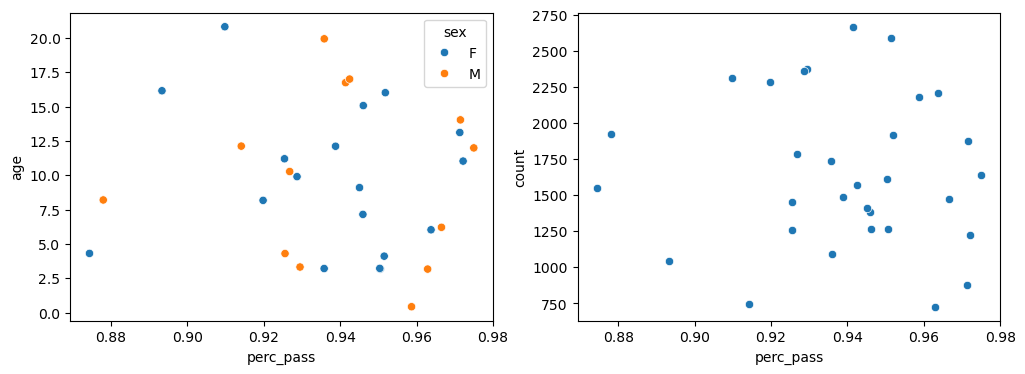

In [19]:
save_sample_stat(adata.obs,['age','sex'],dir=f'/scratch/wyang114/cell-count/all_filter_stats/{region}_{subregion}_mt_filtered.csv')

In [20]:
#Filter out cells with low %intronic reads
intronic_thre = 0.2  #set threshold to filter low %intronic cells
intronic_cell=sum(adata.obs['%intronic']<=intronic_thre)
print(f'filter out {intronic_cell}({intronic_cell/adata_raw*100}%) low %intronic cells.')
adata = adata[adata.obs['%intronic']>intronic_thre,] 
del intronic_cell

filter out 8825(16.131980623343388%) low %intronic cells.


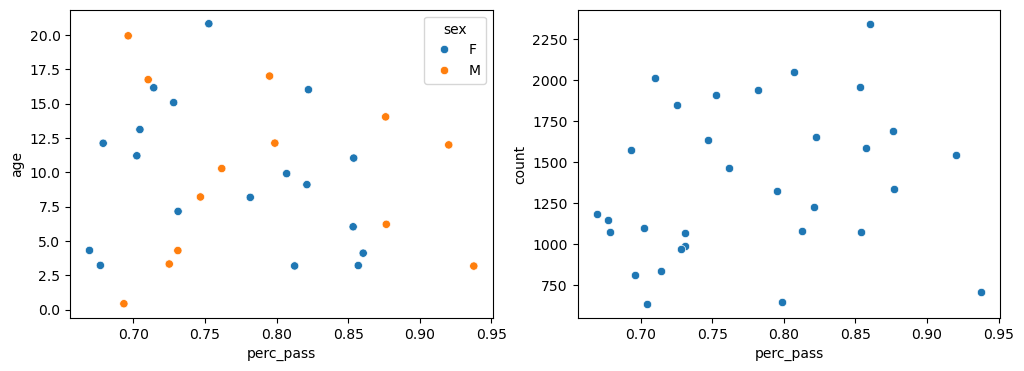

In [21]:
save_sample_stat(adata.obs,['age','sex'],dir=f'/scratch/wyang114/cell-count/all_filter_stats/{region}_{subregion}_intronic_filtered.csv')

In [16]:
#Load filtered data from Kenny's scrublet output
adata = sc.read_h5ad(f'/scratch/klchiou/bican/hdf5/raw_filtered/anndata_rna_{region}-all.h5ad')

In [17]:
adata.obs['region'].value_counts()

region
mdTN    149911
EC       42468
CN       31741
Name: count, dtype: int64

In [18]:
adata = adata[adata.obs['region']=='mdTN',]
adata.raw = adata
adata.obs['total_cell']=adata.obs['sample_id'].map(df_sample)

In [19]:
#Doublet removal: cluster cells at high resolution
adata.raw = adata
adata.obs['total_cell']=adata.obs['sample_id'].map(df_sample)
select_genes = adata.var.index[np.where(~adata.var['chr'].isin(['X','Y']))] # genes mapping to X/Y chr is removed
adata = adata[:,select_genes].copy()
adata.layers['raw'] = adata.X
bioalpha.sc.pp.normalize_total(adata, target_sum=1e4)
bioalpha.sc.pp.log1p(adata)
bioalpha.sc.pp.highly_variable_genes(adata, n_top_genes=10000)
adata = adata[:, adata.var.highly_variable]
adata.layers['normalized_unscaled'] = adata.X
bioalpha.sc.pp.scale(adata, max_value=10)
bioalpha.sc.tl.pca(adata, n_comps=50)
bioalpha.sc.pp.neighbors(adata, n_neighbors=30, n_pcs=30)
bioalpha.sc.tl.louvain(adata, resolution=6)
bioalpha.sc.tl.umap(adata,min_dist=0.25,spread=1.0, n_components=2)

Filtering out 21189 doublets 13.083587010886008%.


/packages/apps/mamba/1.5.1/lib/python3.11/site-packages/scanpy/plotting/_tools/scatterplots.py:394: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


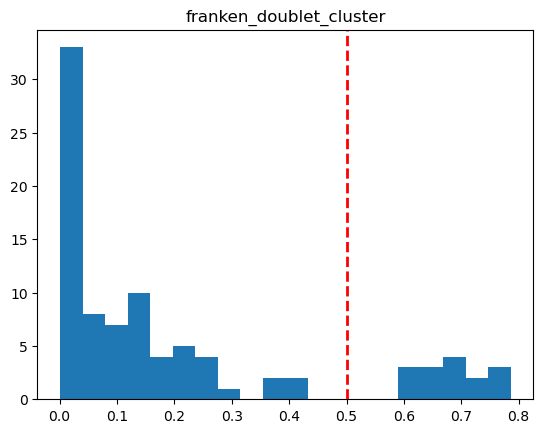

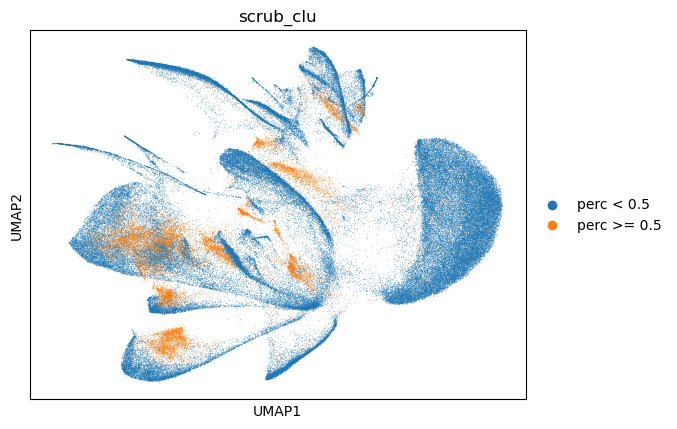

In [33]:
#Doublet removal: filter out clusters with percentage of doublet score > 0.2
df=adata.obs
thre = 0.5
def calculate_doublet_perc(s,thre):
    return (s>thre).mean()
select_clu = df.groupby('louvain')['scrublet_score_from_filtered'].apply(calculate_doublet_perc,thre=0.2)
plt.hist(select_clu,bins=20);
plt.axvline(x=thre, color='red', linestyle='dashed', linewidth=2)
plt.title(f'{region}_doublet_cluster')
select_cells = np.where(df['louvain'].isin(select_clu[select_clu<thre].index)) 
adata.obs['scrub_clu'] = f'perc >= {thre}'
adata.obs.loc[adata.obs.index[select_cells],'scrub_clu']= f'perc < {thre}'
doublets = sum(adata.obs['scrub_clu']==f'perc >= {thre}')
print(f'Filtering out {doublets} doublets {doublets/adata_raw*100}%.')
sc.pl.umap(adata,color='scrub_clu')
#adata = adata[adata.obs['scrub_clu']==f'perc < {thre}']

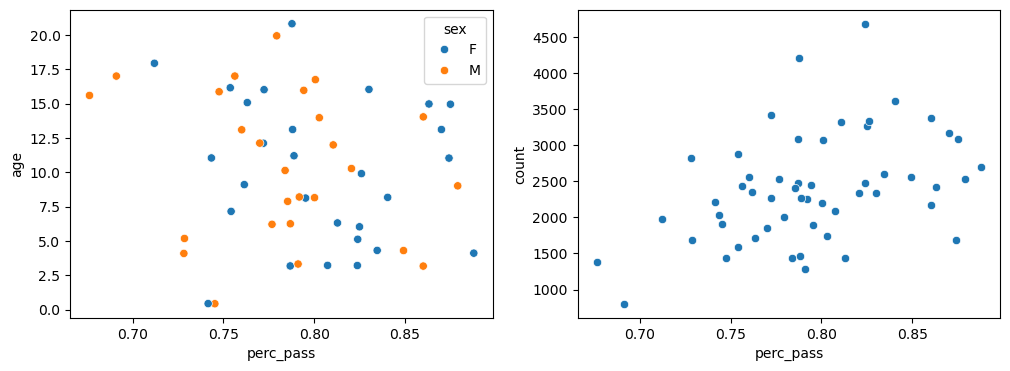

In [23]:
save_sample_stat(adata.obs,['age','sex'],dir=f'/scratch/wyang114/cell-count/all_filter_stats/{region}_{subregion}_doublet_filtered.csv')

In [24]:
#save intermediate file for tacco cell class annotation
adata.write_h5ad("/scratch/wyang114/processed_data/anndata_rna_%s_%s_processed.h5ad"%(region,subregion))

##### Note: Use Run_tacco.py to annotate cell class and subcluster and then use the output for subsequent steps
##### 1. module load mamba/latest
##### 2. source activate TACCO_env
##### 3. open ./Run_tacco_v2.py and change the region param to capitalized region name
##### 4. python ./Run_tacco_v2.py